# 🤖 AI, CA3, Machine Learning 📚  

* **Name** : Amir Parsa🖊  
* **Last Name** : Mobed 📝  
* **SID** : 810100271 🆔

In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached pandas-2.3.3-cp311-cp311-macosx_11_0_arm64.whl (10.8 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 426.1 kB/s eta 0:00:0000:0100:01
  Using cached pytz-2025.2-py2.py3-none-any.whl (509 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.5/348.5 kB 2.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 4.4 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 2.3 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip available: 22.3.1 -> 25.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
import warnings
from pathlib import Path
from typing import Any, Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.multiclass import OneVsRestClassifier

warnings.filterwarnings("ignore")
np.random.seed(42)
pd.set_option("display.max_columns", 200)


## Part 1 – Decision Tree From Scratch

Implementing a binary classifier from scratch and comparing it with `sklearn` on the provided Section 1 datasets.

### Custom Decision Tree implementation

In [18]:
class TreeNode:
    '''Lightweight tree node.'''

    def __init__(
        self,
        *,
        depth: int,
        prediction: Any = None,
        feature: str | None = None,
        threshold: float | None = None,
        children: Dict[Any, "TreeNode"] | None = None,
        is_categorical: bool = False,
    ):
        self.depth = depth
        self.prediction = prediction
        self.feature = feature
        self.threshold = threshold
        self.children = children or {}
        self.is_categorical = is_categorical

    @property
    def is_leaf(self) -> bool:
        return self.feature is None


class MyDecisionTree:
    def __init__(
        self,
        max_depth: int = 3,
        min_samples_split: int = 2,
        criterion: str = "gini",
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion
        self.root: TreeNode | None = None
        self.classes_: np.ndarray | None = None

    # --- impurity helpers -------------------------------------------------
    def _gini(self, y: np.ndarray) -> float:
        _, counts = np.unique(y, return_counts=True)
        probs = counts / counts.sum()
        return 1.0 - np.sum(probs ** 2)

    def _entropy(self, y: np.ndarray) -> float:
        _, counts = np.unique(y, return_counts=True)
        probs = counts / counts.sum()
        return -np.sum(probs * np.log2(probs + 1e-12))

    def _impurity(self, y: np.ndarray) -> float:
        return self._gini(y) if self.criterion == "gini" else self._entropy(y)

    # --- splitting logic --------------------------------------------------
    def _best_numeric_split(self, feature: str, X: pd.DataFrame, y: np.ndarray) -> Tuple[float, float, np.ndarray]:
        values = X[feature].astype(float).values
        order = np.argsort(values)
        values, y_sorted = values[order], y[order]
        unique_values = np.unique(values)
        if unique_values.size == 1:
            return np.inf, None, None
        thresholds = (unique_values[:-1] + unique_values[1:]) / 2.0

        best_gain, best_thresh, best_mask = -np.inf, None, None
        parent_impurity = self._impurity(y_sorted)
        n = len(y_sorted)
        for thresh in thresholds:
            left_mask = values <= thresh
            right_mask = ~left_mask
            if left_mask.sum() < self.min_samples_split or right_mask.sum() < self.min_samples_split:
                continue
            left_imp = self._impurity(y_sorted[left_mask])
            right_imp = self._impurity(y_sorted[right_mask])
            weighted = (left_mask.sum() * left_imp + right_mask.sum() * right_imp) / n
            gain = parent_impurity - weighted
            if gain > best_gain:
                best_gain, best_thresh, best_mask = gain, float(thresh), left_mask
        return best_gain, best_thresh, best_mask

    def _best_categorical_split(self, feature: str, X: pd.DataFrame, y: np.ndarray) -> Tuple[float, Dict[Any, np.ndarray]]:
        parent_impurity = self._impurity(y)
        best_gain, best_masks = -np.inf, {}
        n = len(y)
        for val in X[feature].unique():
            mask = X[feature] == val
            if mask.sum() < self.min_samples_split:
                continue
            impurity = self._impurity(y[mask])
            weighted = (mask.sum() * impurity + (n - mask.sum()) * self._impurity(y[~mask])) / n
            gain = parent_impurity - weighted
            if gain > best_gain:
                best_gain, best_masks = gain, {val: mask, "__other__": ~mask}
        return best_gain, best_masks

    def _majority_label(self, y: np.ndarray) -> Any:
        values, counts = np.unique(y, return_counts=True)
        return values[counts.argmax()]

    def _build(self, X: pd.DataFrame, y: np.ndarray, depth: int) -> TreeNode:
        if depth >= self.max_depth or len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return TreeNode(depth=depth, prediction=self._majority_label(y))

        best_feature, best_gain, best_threshold = None, -np.inf, None
        best_children = None
        is_categorical = False

        for feature in X.columns:
            if X[feature].dtype == object:
                gain, masks = self._best_categorical_split(feature, X, y)
                if gain > best_gain and masks:
                    best_feature, best_gain, best_threshold = feature, gain, None
                    best_children = masks
                    is_categorical = True
            else:
                gain, thresh, mask = self._best_numeric_split(feature, X, y)
                if gain > best_gain and mask is not None:
                    best_feature, best_gain, best_threshold = feature, gain, thresh
                    best_children = {"<=": mask, ">": ~mask}
                    is_categorical = False

        if best_feature is None:
            return TreeNode(depth=depth, prediction=self._majority_label(y))

        node = TreeNode(
            depth=depth,
            feature=best_feature,
            threshold=best_threshold,
            is_categorical=is_categorical,
        )

        for key, mask in best_children.items():
            child_X = X.loc[mask]
            child_y = y[mask]
            node.children[key] = self._build(child_X, child_y, depth + 1)
        return node

    def fit(self, X: pd.DataFrame, y: pd.Series):
        df = X.copy().reset_index(drop=True)
        y_arr = np.asarray(y)
        self.classes_ = np.unique(y_arr)
        self.root = self._build(df, y_arr, depth=0)
        return self

    def _predict_one(self, row: pd.Series, node: TreeNode) -> Any:
        if node.is_leaf:
            return node.prediction
        value = row[node.feature]
        if node.is_categorical:
            key = value if value in node.children else "__other__"
            return self._predict_one(row, node.children.get(key, list(node.children.values())[0]))
        else:
            branch = "<=" if float(value) <= node.threshold else ">"
            return self._predict_one(row, node.children[branch])

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        assert self.root is not None, "Model not fitted."
        df = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        return np.array([self._predict_one(row, self.root) for _, row in df.iterrows()])

    def score(self, X: pd.DataFrame, y: pd.Series) -> float:
        preds = self.predict(X)
        return accuracy_score(y, preds)

    def print_tree(self, node: TreeNode | None = None, indent: str = ""):
        node = node or self.root
        if node is None:
            print("[Empty tree]")
            return
        if node.is_leaf:
            print(f"{indent}Leaf -> predict {node.prediction}")
            return
        if node.is_categorical:
            print(f"{indent}if {node.feature} in {list(node.children.keys())}:")
            for key, child in node.children.items():
                self.print_tree(child, indent + "  ")
        else:
            print(f"{indent}if {node.feature} <= {node.threshold:.3f}:")
            self.print_tree(node.children["<="], indent + "  ")
            print(f"{indent}else:")
            self.print_tree(node.children[">"] , indent + "  ")


### Helper utilities

In [19]:
def binary_metrics(y_true, y_pred) -> Dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def show_confusion(y_true, y_pred, labels, title: str):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                       xticklabels=labels, yticklabels=labels)
    disp.set_xlabel("Predicted")
    disp.set_ylabel("True")
    disp.set_title(title)
    plt.show()


def prepare_split(df: pd.DataFrame, target: str, test_size: float = 0.3):
    X = df.drop(columns=[target])
    y = df[target]
    return train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y,
    )


### Section 1 – dataset without `avg_previous_grade`
Train/evaluate the custom tree and compare with `sklearn`'s implementation.

Custom tree metrics: {'accuracy': 0.78, 'precision': 0.8333333333333334, 'recall': 0.8495145631067961, 'f1': 0.8413461538461539}
if prog_skill in ['Low', '__other__']:
  if meetings_per_week <= 2.500:
    if meetings_per_week <= 3.500:
      if meetings_per_week <= 3.500:
        Leaf -> predict 0
      else:
        Leaf -> predict 0
    else:
      if meetings_per_week <= 2.500:
        Leaf -> predict 0
      else:
        Leaf -> predict 0
  else:
    if meetings_per_week <= 2.500:
      if meetings_per_week <= 2.500:
        Leaf -> predict 0
      else:
        Leaf -> predict 0
    else:
      if meetings_per_week <= 2.500:
        Leaf -> predict 0
      else:
        Leaf -> predict 0
  if meetings_per_week <= 1.500:
    if meetings_per_week <= 0.500:
      if group_size <= 3.500:
        Leaf -> predict 1
      else:
        Leaf -> predict 1
    else:
      if meetings_per_week <= 1.500:
        Leaf -> predict 1
      else:
        Leaf -> predict 1
  else:
    if meetings_

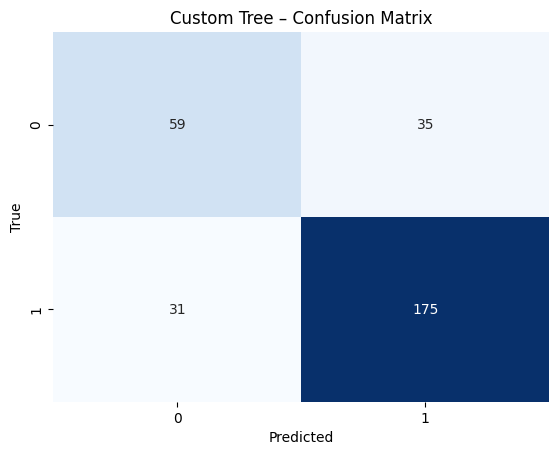

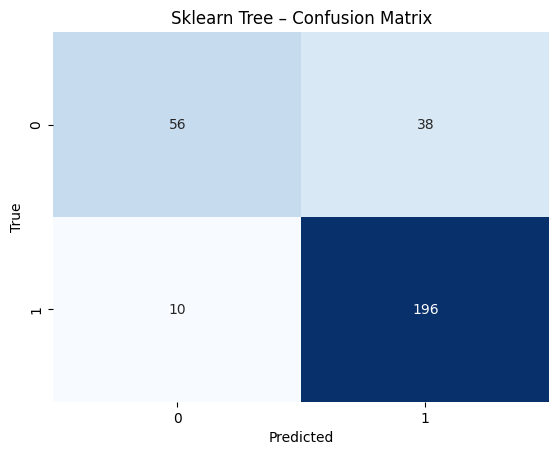

In [21]:
s1_part1 = pd.read_csv("s1_part1_dataset.csv")
X_train, X_val, y_train, y_val = prepare_split(s1_part1, target="Is_finished")

custom_tree = MyDecisionTree(max_depth=4, min_samples_split=5, criterion="gini")
custom_tree.fit(X_train, y_train)
custom_preds = custom_tree.predict(X_val)
custom_scores = binary_metrics(y_val, custom_preds)
print("Custom tree metrics:", custom_scores)
custom_tree.print_tree()

# sklearn baseline with one-hot for categorical prog_skill
cat_cols = ["prog_skill"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
preprocess = ColumnTransformer(
    [
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)
sk_tree = Pipeline(
    steps=[
        ("prep", preprocess),
        (
            "clf",
            DecisionTreeClassifier(random_state=42, max_depth=4, min_samples_split=5),
        ),
    ]
)
sk_tree.fit(X_train, y_train)
sk_preds = sk_tree.predict(X_val)
sk_scores = binary_metrics(y_val, sk_preds)
print("Sklearn tree metrics:", sk_scores)

show_confusion(y_val, custom_preds, labels=[0, 1], title="Custom Tree – Confusion Matrix")
show_confusion(y_val, sk_preds, labels=[0, 1], title="Sklearn Tree – Confusion Matrix")


### Depth sensitivity (max_depth = 1)
Re-train shallow trees to inspect overfitting vs. bias.

In [22]:
shallow_tree = MyDecisionTree(max_depth=1, min_samples_split=2)
shallow_tree.fit(X_train, y_train)
shallow_preds = shallow_tree.predict(X_val)
print("Custom shallow depth-1:", binary_metrics(y_val, shallow_preds))

shallow_sk_tree = Pipeline(
    steps=[
        ("prep", preprocess),
        ("clf", DecisionTreeClassifier(random_state=42, max_depth=1)),
    ]
)
shallow_sk_tree.fit(X_train, y_train)
print("Sklearn shallow depth-1:", binary_metrics(y_val, shallow_sk_tree.predict(X_val)))


Custom shallow depth-1: {'accuracy': 0.78, 'precision': 0.8333333333333334, 'recall': 0.8495145631067961, 'f1': 0.8413461538461539}
Sklearn shallow depth-1: {'accuracy': 0.78, 'precision': 0.8333333333333334, 'recall': 0.8495145631067961, 'f1': 0.8413461538461539}


### Section 1 – dataset **with** `avg_previous_grade`
Replicate the experiment to show the effect of the new feature.

In [24]:
s1_part2 = pd.read_csv("s1_part2_dataset.csv")
X_train2, X_val2, y_train2, y_val2 = prepare_split(s1_part2, target="Is_finished")
cat_cols2 = ["prog_skill"]
num_cols2 = [c for c in X_train2.columns if c not in cat_cols2]
preprocess2 = ColumnTransformer(
    [
        ("num", "passthrough", num_cols2),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols2),
    ]
)

custom_tree2 = MyDecisionTree(max_depth=3, min_samples_split=4, criterion="gini")
custom_tree2.fit(X_train2, y_train2)
custom_preds2 = custom_tree2.predict(X_val2)
print("Custom (new feature):", binary_metrics(y_val2, custom_preds2))

sk_tree2 = Pipeline(
    steps=[
        ("prep", preprocess2),
        (
            "clf",
            DecisionTreeClassifier(random_state=42, max_depth=3, min_samples_split=4),
        ),
    ]
)
sk_tree2.fit(X_train2, y_train2)
print("Sklearn (new feature):", binary_metrics(y_val2, sk_tree2.predict(X_val2)))

shallow_sk_tree2 = Pipeline(
    steps=[
        ("prep", preprocess2),
        ("clf", DecisionTreeClassifier(random_state=42, max_depth=1)),
    ]
)
shallow_sk_tree2.fit(X_train2, y_train2)
print("Sklearn depth-1 (new feature):", binary_metrics(y_val2, shallow_sk_tree2.predict(X_val2)))


Custom (new feature): {'accuracy': 0.6866666666666666, 'precision': 0.6866666666666666, 'recall': 1.0, 'f1': 0.8142292490118577}
Sklearn (new feature): {'accuracy': 0.95, 'precision': 0.95260663507109, 'recall': 0.9757281553398058, 'f1': 0.9640287769784173}
Sklearn depth-1 (new feature): {'accuracy': 0.95, 'precision': 0.9441860465116279, 'recall': 0.9854368932038835, 'f1': 0.9643705463182898}


### Export predictions for Section 1 test files

In [27]:
def export_predictions(model, preprocess, test_path: str, out_path: str):
    test_df = pd.read_csv(test_path)
    preds = model.predict(test_df)
    out = test_df.copy()
    out["Is_finished"] = preds
    out.to_csv(out_path, index=False)
    print(f"Saved predictions to {out_path}")

# Use the better-performing sklearn pipelines for reproducible outputs
export_predictions(sk_tree, preprocess, "s1_part1_test.csv", "s1_part1_predictions.csv")
export_predictions(sk_tree2, preprocess2, "s1_part2_test.csv", "s1_part2_predictions.csv")


Saved predictions to s1_part1_predictions.csv
Saved predictions to s1_part2_predictions.csv


## Part 2 – Email importance vs. spam
The preprocessing utilities are provided; the following cells finish the pipeline and train Naive Bayes and Decision Tree models with both binary and count-based bag-of-words vectors.

In [29]:
%pip install nltk

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 172.4 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.3/108.3 kB 484.1 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.4/288.4 kB 85.8 kB/s eta 0:00:00a 0:00:01
  Using cached tqdm-4.67.1-py3-none-any.whl (78 kB)

[notice] A new release of pip available: 22.3.1 -> 25.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [38]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [
        lemmatizer.lemmatize(tok)
        for tok in text.split()
        if tok and tok not in stop_words
    ]
    return " ".join(tokens)


NaiveBayes (binary vectors) metrics: {'accuracy': 0.8888888888888888, 'precision': 0.8260869565217391, 'recall': 1.0, 'f1': 0.9047619047619048}


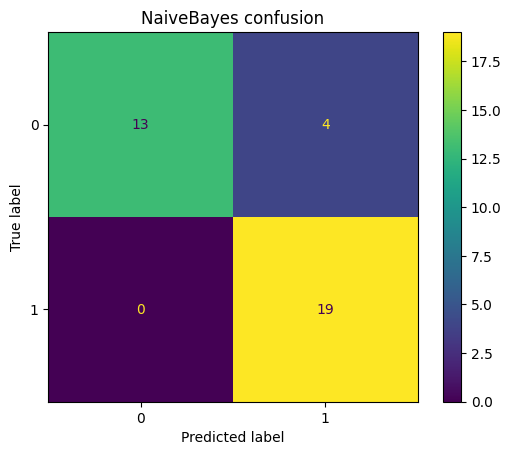

DecisionTree (binary vectors) metrics: {'accuracy': 0.75, 'precision': 0.7272727272727273, 'recall': 0.8421052631578947, 'f1': 0.7804878048780488}


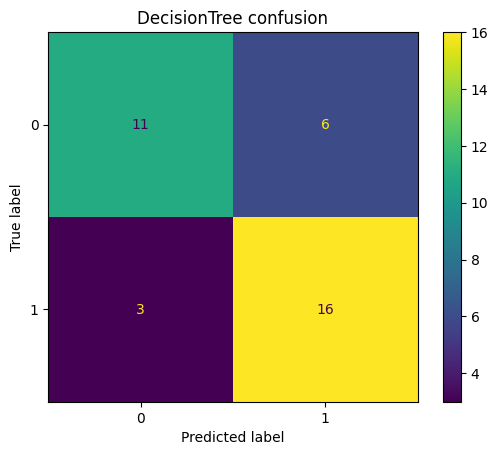

NaiveBayes (count vectors) metrics: {'accuracy': 0.9444444444444444, 'precision': 0.9047619047619048, 'recall': 1.0, 'f1': 0.95}


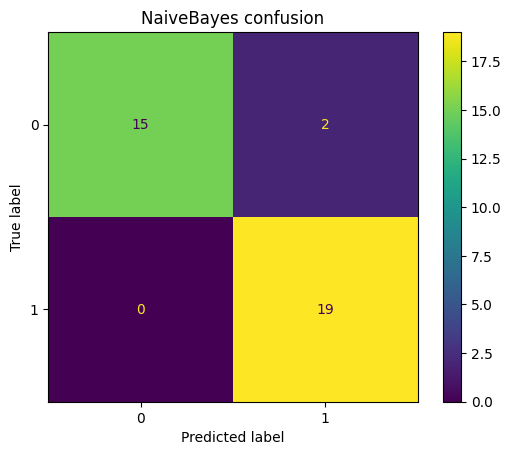

DecisionTree (count vectors) metrics: {'accuracy': 0.75, 'precision': 0.7272727272727273, 'recall': 0.8421052631578947, 'f1': 0.7804878048780488}


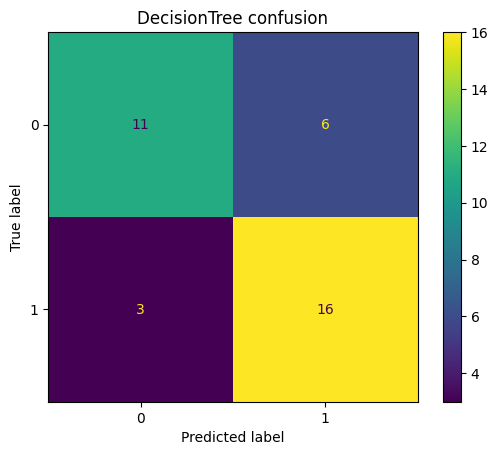

In [56]:
from sklearn.metrics import ConfusionMatrixDisplay

emails_path = Path("part2_dataset.csv")
part2_test_path = Path("part2_test.csv")


def run_email_experiment(binary: bool = True):
    if not emails_path.exists():
        print("Email dataset not found.")
        return None
    df = pd.read_csv(emails_path)
    text_col = "text" if "text" in df.columns else df.columns[0]
    label_col = "is_important" if "is_important" in df.columns else df.columns[-1]

    df[text_col] = df[text_col].apply(clean_text)
    X_train, X_val, y_train, y_val = train_test_split(
        df[text_col], df[label_col], test_size=0.3, random_state=42, stratify=df[label_col]
    )

    vectorizer = CountVectorizer(binary=binary)
    nb_cls = BernoulliNB() if binary else MultinomialNB()

    nb_model = Pipeline([
        ("vec", vectorizer),
        ("clf", nb_cls),
    ])

    tree_model = Pipeline([
        ("vec", vectorizer),
        ("clf", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ])

    results = {}
    for name, model in [("NaiveBayes", nb_model), ("DecisionTree", tree_model)]:
        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        scores = binary_metrics(y_val, preds)
        results[name] = scores
        print(f"{name} ({'binary' if binary else 'count'} vectors) metrics: {scores}")
        ConfusionMatrixDisplay.from_predictions(y_val, preds)
        plt.title(f"{name} confusion")
        plt.show()
    return results

binary_results = run_email_experiment(binary=True)
count_results = run_email_experiment(binary=False)


In [58]:
if emails_path.exists() and part2_test_path.exists():
    email_df = pd.read_csv(emails_path)
    text_col = "text" if "text" in email_df.columns else email_df.columns[0]
    label_col = "is_important" if "is_important" in email_df.columns else email_df.columns[-1]
    email_df[text_col] = email_df[text_col].apply(clean_text)

    final_vec = CountVectorizer(binary=True)
    final_model = Pipeline([
        ("vec", final_vec),
        ("clf", BernoulliNB()),
    ])
    final_model.fit(email_df[text_col], email_df[label_col])

    test_df = pd.read_csv(part2_test_path)
    test_df[text_col] = test_df[text_col].apply(clean_text)
    test_preds = final_model.predict(test_df[text_col])
    out = test_df.copy()
    out[label_col] = test_preds
    out.to_csv("part2_predictions.csv", index=False)
    print("Saved part2 predictions to part2_predictions.csv")
else:
    print("Skip exporting part2 predictions (dataset not present).")


Saved part2 predictions to part2_predictions.csv


## Part 3 – Multi-class crisis type prediction
Includes preprocessing, decision tree baseline, ensemble upgrades, and a manual one-vs-rest scheme.

Best params: {'clf__max_depth': 7, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 2}
              precision    recall  f1-score   support

 Denial_mode       0.96      0.94      0.95       264
    No_issue       0.93      0.95      0.94       478
  panic_mode       0.95      0.94      0.95       458

    accuracy                           0.94      1200
   macro avg       0.95      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200



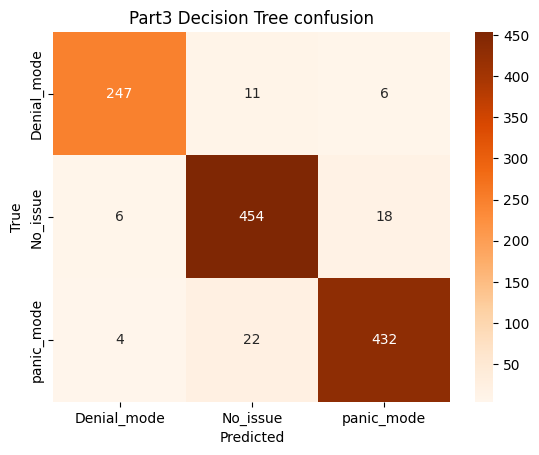

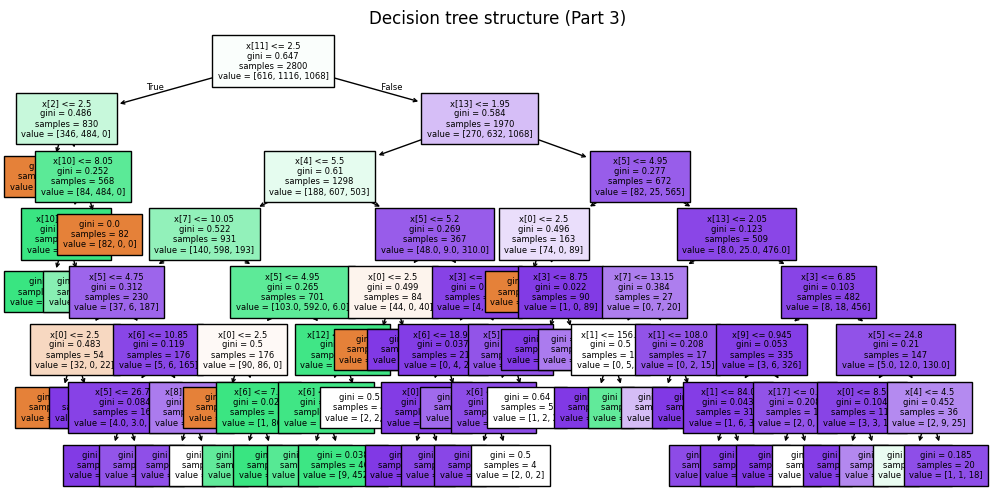

In [42]:
part3_df = pd.read_csv("part3_dataset.csv")
part3_test_df = pd.read_csv("part3_test.csv")

numeric_cols_p3 = [c for c in part3_df.columns if part3_df[c].dtype != object and c != "crisis_type"]
categorical_cols_p3 = [c for c in part3_df.columns if part3_df[c].dtype == object and c != "crisis_type"]


def preprocess_part3(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()
    # Handle missing values
    for col in numeric_cols_p3:
        data[col] = data[col].fillna(data[col].median())
    for col in categorical_cols_p3:
        data[col] = data[col].fillna(data[col].mode().iloc[0])

    # Clip outliers to reasonable quantiles
    quantiles = data[numeric_cols_p3].quantile([0.01, 0.99])
    data[numeric_cols_p3] = data[numeric_cols_p3].clip(quantiles.loc[0.01], quantiles.loc[0.99], axis=1)

    # Feature engineering
    data["study_effort_ratio"] = data["hours_studied_last_week"] / (data["days_before_started_study"] + 1)
    data["sleep_deficit"] = np.maximum(0, 7 - data["sleep_hours_before_exam"])
    return data


def build_part3_preprocessor(scale_numeric: bool = False) -> ColumnTransformer:
    numeric_features = numeric_cols_p3 + ["study_effort_ratio", "sleep_deficit"]
    cat_features = categorical_cols_p3
    numeric_pipe = Pipeline(
        steps=[
            ("imputer", "passthrough"),
            ("scaler", StandardScaler() if scale_numeric else "passthrough"),
        ]
    )
    cat_pipe = Pipeline(
        steps=[
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    return ColumnTransformer(
        [
            ("num", numeric_pipe, numeric_features),
            ("cat", cat_pipe, cat_features),
        ]
    )


clean_part3 = preprocess_part3(part3_df)
X3 = clean_part3.drop(columns=["crisis_type"])
y3 = clean_part3["crisis_type"]
X3_train, X3_val, y3_train, y3_val = train_test_split(
    X3, y3, test_size=0.3, random_state=42, stratify=y3
)

preprocessor3 = build_part3_preprocessor(scale_numeric=False)

dt3 = Pipeline(
    steps=[
        ("prep", preprocessor3),
        (
            "clf",
            DecisionTreeClassifier(random_state=42),
        ),
    ]
)

param_grid = {
    "clf__max_depth": [3, 5, 7, None],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
}

search_dt3 = GridSearchCV(dt3, param_grid, cv=3, n_jobs=-1)
search_dt3.fit(X3_train, y3_train)
print("Best params:", search_dt3.best_params_)

best_dt3 = search_dt3.best_estimator_
y3_val_pred = best_dt3.predict(X3_val)
print(classification_report(y3_val, y3_val_pred))

cm3 = confusion_matrix(y3_val, y3_val_pred, labels=sorted(y3.unique()))
sns.heatmap(cm3, annot=True, fmt="d", cmap="Oranges", xticklabels=sorted(y3.unique()), yticklabels=sorted(y3.unique()))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Part3 Decision Tree confusion")
plt.show()

plt.figure(figsize=(12, 6))
plot_tree(best_dt3["clf"], filled=True, fontsize=6)
plt.title("Decision tree structure (Part 3)")
plt.show()


### Ensembles (Bagging/RandomForest + Boosting)
Try stronger learners and tune with randomized/grid search.

In [43]:
rf_pipe = Pipeline(
    steps=[
        ("prep", preprocessor3),
        ("clf", RandomForestClassifier(random_state=42)),
    ]
)
rf_params = {
    "clf__n_estimators": [150, 250],
    "clf__max_depth": [None, 8, 12],
    "clf__max_features": ["auto", "sqrt"],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=6, cv=3, n_jobs=-1, random_state=42)
rf_search.fit(X3_train, y3_train)
print("RF best params:", rf_search.best_params_)

ada_pipe = Pipeline(
    steps=[
        ("prep", preprocessor3),
        ("clf", AdaBoostClassifier(random_state=42)),
    ]
)
ada_params = {
    "clf__n_estimators": [50, 100, 200],
    "clf__learning_rate": [0.5, 0.8, 1.0],
}
ada_search = GridSearchCV(ada_pipe, ada_params, cv=3, n_jobs=-1)
ada_search.fit(X3_train, y3_train)
print("AdaBoost best params:", ada_search.best_params_)

for name, model in {
    "RandomForest": rf_search.best_estimator_,
    "AdaBoost": ada_search.best_estimator_,
}.items():
    preds = model.predict(X3_val)
    print(f"{name} metrics:", classification_report(y3_val, preds))


RF best params: {'clf__n_estimators': 150, 'clf__max_features': 'sqrt', 'clf__max_depth': 12}
AdaBoost best params: {'clf__learning_rate': 0.8, 'clf__n_estimators': 200}
RandomForest metrics:               precision    recall  f1-score   support

 Denial_mode       0.99      0.93      0.96       264
    No_issue       0.96      0.95      0.96       478
  panic_mode       0.94      0.98      0.96       458

    accuracy                           0.96      1200
   macro avg       0.97      0.96      0.96      1200
weighted avg       0.96      0.96      0.96      1200

AdaBoost metrics:               precision    recall  f1-score   support

 Denial_mode       0.73      0.33      0.45       264
    No_issue       0.75      0.91      0.82       478
  panic_mode       0.88      0.96      0.92       458

    accuracy                           0.80      1200
   macro avg       0.79      0.73      0.73      1200
weighted avg       0.79      0.80      0.78      1200



### Manual One-vs-Rest with Decision Trees

In [44]:
preprocessor3.fit(X3_train)
X3_train_enc = preprocessor3.transform(X3_train)
X3_val_enc = preprocessor3.transform(X3_val)
classes = sorted(y3.unique())

ovr_models = {}
for cls in classes:
    y_bin = (y3_train == cls).astype(int)
    clf = DecisionTreeClassifier(max_depth=6, random_state=42)
    clf.fit(X3_train_enc, y_bin)
    ovr_models[cls] = clf

val_probs = np.column_stack([model.predict_proba(X3_val_enc)[:, 1] for model in ovr_models.values()])
val_preds = [classes[idx] for idx in val_probs.argmax(axis=1)]
print("One-vs-Rest metrics:", classification_report(y3_val, val_preds))


One-vs-Rest metrics:               precision    recall  f1-score   support

 Denial_mode       0.97      0.95      0.96       264
    No_issue       0.97      0.95      0.96       478
  panic_mode       0.94      0.97      0.96       458

    accuracy                           0.96      1200
   macro avg       0.96      0.96      0.96      1200
weighted avg       0.96      0.96      0.96      1200



### Export Part 3 predictions using the strongest ensemble

In [47]:
best_model_p3 = rf_search.best_estimator_
clean_test3 = preprocess_part3(part3_test_df)
test_preds_p3 = best_model_p3.predict(clean_test3)
out3 = clean_test3.copy()
out3["crisis_type"] = test_preds_p3
out3.to_csv("part3_predictions.csv", index=False)
print("Saved part3 predictions to part3_predictions.csv")


Saved part3 predictions to part3_predictions.csv


## Part 4 – Final exam score regression
Reuse the preprocessing from Part 3, compare three regressors, compute metrics manually, and run a bias–variance probe.

In [50]:
%pip install xgboost

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 3.5 MB/s eta 0:00:00a 0:00:010m

[notice] A new release of pip available: 22.3.1 -> 25.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [51]:
part4_df = pd.read_csv("part4_dataset.csv")
part4_test_df = pd.read_csv("part4_test.csv")


def preprocess_part4(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()
    num_cols = [c for c in data.columns if data[c].dtype != object and c not in ["final_exam_score"]]
    cat_cols = [c for c in data.columns if data[c].dtype == object]

    for col in num_cols:
        data[col] = data[col].fillna(data[col].median())
    for col in cat_cols:
        data[col] = data[col].fillna(data[col].mode().iloc[0])

    quant = data[num_cols].quantile([0.01, 0.99])
    data[num_cols] = data[num_cols].clip(quant.loc[0.01], quant.loc[0.99], axis=1)

    data["study_effort_ratio"] = data["hours_studied_last_week"] / (data["days_before_started_study"] + 1)
    data["sleep_deficit"] = np.maximum(0, 7 - data["sleep_hours_before_exam"])
    return data


def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    mse = float(np.mean((y_true - y_pred) ** 2))
    mae = float(np.mean(np.abs(y_true - y_pred)))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return {"mse": mse, "mae": mae, "r2": r2}


clean_part4 = preprocess_part4(part4_df)
X4 = clean_part4.drop(columns=["final_exam_score"])
y4 = clean_part4["final_exam_score"]
X4_train, X4_val, y4_train, y4_val = train_test_split(
    X4, y4, test_size=0.3, random_state=42
)

numeric_cols_p4 = [c for c in X4_train.columns if X4_train[c].dtype != object]
cat_cols_p4 = [c for c in X4_train.columns if X4_train[c].dtype == object]
preprocessor4 = ColumnTransformer(
    [
        ("num", Pipeline([("scaler", StandardScaler())]), numeric_cols_p4),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_p4),
    ]
)

regressors = {
    "DecisionTree": DecisionTreeRegressor(random_state=42, max_depth=6),
    "RandomForest": RandomForestRegressor(random_state=42, n_estimators=200),
}

from xgboost import XGBRegressor

regressors["XGBRegressor"] = XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror",
)

results_p4 = {}
for name, model in regressors.items():
    pipe = Pipeline([
        ("prep", preprocessor4),
        ("model", model),
    ])
    pipe.fit(X4_train, y4_train)
    preds = pipe.predict(X4_val)
    results_p4[name] = regression_metrics(y4_val, preds)
    print(f"{name} metrics: {results_p4[name]}")


DecisionTree metrics: {'mse': 6.832146757243271, 'mae': 1.8856754951759305, 'r2': np.float64(0.652654889483866)}
RandomForest metrics: {'mse': 6.142041392916668, 'mae': 1.7336450000000005, 'r2': np.float64(0.6877397219028523)}
XGBRegressor metrics: {'mse': 6.366214452310365, 'mae': 1.788843067487081, 'r2': np.float64(0.676342803941848)}


### Bias–Variance probe
Repeated sub-sampling to visualize spread of predictions for a fixed input point.

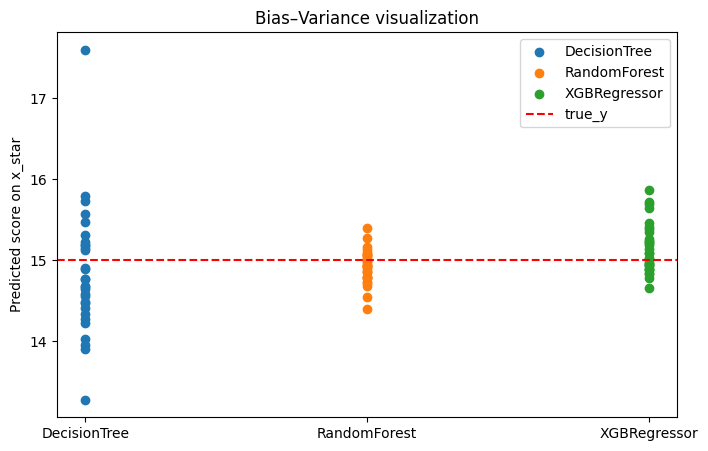

In [52]:
x_star = X4_val.sample(1, random_state=123)
iterations = 30

scatter_data = {name: [] for name in regressors}
true_y = float(y4.loc[x_star.index[0]])

for i in range(iterations):
    X_boot, _, y_boot, _ = train_test_split(X4, y4, test_size=0.7, random_state=42 + i)
    for name, model in regressors.items():
        pipe = Pipeline([
            ("prep", preprocessor4),
            ("model", model),
        ])
        pipe.fit(X_boot, y_boot)
        pred = float(pipe.predict(x_star)[0])
        scatter_data[name].append(pred)

plt.figure(figsize=(8, 5))
for idx, (name, preds) in enumerate(scatter_data.items()):
    plt.scatter([idx] * len(preds), preds, label=name)
plt.axhline(true_y, color="red", linestyle="--", label="true_y")
plt.xticks(range(len(scatter_data)), list(scatter_data.keys()))
plt.ylabel("Predicted score on x_star")
plt.legend()
plt.title("Bias–Variance visualization")
plt.show()


### Export Part 4 predictions

In [53]:
best_reg_name = min(results_p4, key=lambda k: results_p4[k]["mse"])
print("Using best regressor:", best_reg_name)

best_reg = regressors[best_reg_name]
best_pipe = Pipeline([
    ("prep", preprocessor4),
    ("model", best_reg),
])
best_pipe.fit(X4, y4)

clean_test4 = preprocess_part4(part4_test_df)
test_preds4 = best_pipe.predict(clean_test4)
out4 = clean_test4.copy()
out4["final_exam_score"] = test_preds4
out4.to_csv("part4_predictions.csv", index=False)
print("Saved part4 predictions to part4_predictions.csv")

Using best regressor: RandomForest
Saved part4 predictions to part4_predictions.csv
